# 02 — Baseline and proposed architecture: species classifier

**Phase I evidence**: working baseline with an initial metric (5), architecture implementation and justification (6), training choices and learning curves (5), baseline comparison (4).

Two models on the same 13-class split (`empty` + 12 species) produced by `src/vision/make_splits.py`:

1. **Baseline** — frozen ImageNet ResNet-50 features + a logistic-regression head. No deep training at all, so it is the honest reference the rubric asks for.
2. **Proposed** — the same backbone with the classifier head replaced and the last block unfrozen, trained end to end with cross-entropy, AdamW and inverse-frequency class weights.

Executed locally on the RTX 3060 Laptop over the full split. A cloud-GPU replication was attempted and withdrawn (see `docs/SOURCE_LOG.md` row 11), so the numbers in this notebook come from one machine and one seed.


In [1]:
import json, os, sys, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch.utils.data import DataLoader
from torchvision import transforms as T
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier

ON_KAGGLE = Path("/kaggle/input").exists()
if ON_KAGGLE:
    # Kaggle mounts attached datasets at /kaggle/input/<slug>/ in the old layout and at
    # /kaggle/input/datasets/<owner>/<slug>/ in the current one (measured 2026-10-24 by kernel
    # shivam2212/p11-mount-probe: 217,651 files, 11.42 GB, weights at
    # /kaggle/input/datasets/shivam2212/p11-weights/resnet50-11ad3fa6.pth). Assuming depth 1 is what made
    # the first two pushes fail. Candidate dirs are therefore collected to depth 3, and never below that:
    # recursing into the image corpus costs hours and buys nothing.
    INPUTS = Path("/kaggle/input")
    cand = [d for d in INPUTS.iterdir() if d.is_dir()]
    for d in list(cand):
        if d.name == "datasets":
            for owner in (o for o in d.iterdir() if o.is_dir()):
                cand += [s for s in owner.iterdir() if s.is_dir()]
    print("mount candidates:", sorted(str(c) for c in cand))
    MIRROR = next((d for d in cand if (d / "iwildcam_v2.0" / "train").is_dir()), None)
    AUX = next((d for d in cand if (d / "splits" / "train.csv").exists()), None)
    PTHS = [p for d in cand if d != MIRROR for p in sorted(d.glob("*.pth"))]
    assert MIRROR, "no mounted directory contains iwildcam_v2.0/train"
    assert AUX, "no mounted directory contains splits/train.csv"
    assert PTHS, "no .pth weights mounted outside the image corpus"
    WEIGHTS = PTHS[0]
    IMG_ROOT = MIRROR / "iwildcam_v2.0" / "train"
    SPLITS_DIR = AUX / "splits"
    OUT = Path("/kaggle/working")
    sys.path.insert(0, str(AUX / "src"))
    print("weights:", WEIGHTS, "| images:", IMG_ROOT)
else:
    ROOT = next(a for a in [Path.cwd(), *Path.cwd().parents] if (a / "data/splits").exists())
    IMG_ROOT = ROOT / "data/raw/iwildcam_v2.0/train"
    SPLITS_DIR = ROOT / "data/splits"
    WEIGHTS = Path(os.path.expanduser("~/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth"))
    OUT = Path(os.environ.get("P11_OUT", ROOT / "outputs/logs/notebook02"))
    sys.path.insert(0, str(ROOT / "src/vision"))

import wildlife as W

assert IMG_ROOT.is_dir(), f"no image directory at {IMG_ROOT}"
assert WEIGHTS.is_file(), f"no weights file at {WEIGHTS}"
OUT.mkdir(parents=True, exist_ok=True)
SEED = int(os.environ.get("P11_SEED", W.SEED))
LIMIT = int(os.environ.get("P11_LIMIT", 0))
BATCH = int(os.environ.get("P11_BATCH", 64))
EPOCHS = int(os.environ.get("P11_EPOCHS", 30))
LR = float(os.environ.get("P11_LR", 1e-4))
W.set_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(json.dumps({"on_kaggle": ON_KAGGLE, "seed": SEED, "limit": LIMIT, "batch": BATCH,
                  "epochs": EPOCHS, "lr": LR, "img_root": str(IMG_ROOT),
                  "weights": str(WEIGHTS), "out": str(OUT), **W.hardware_note()}, indent=2))


{
  "on_kaggle": false,
  "seed": 13,
  "limit": 0,
  "batch": 64,
  "epochs": 8,
  "lr": 0.0001,
  "img_root": "C:\\Users\\xxshi\\Desktop\\PYTHOM\\DL_PBL\\data\\raw\\iwildcam_v2.0\\train",
  "weights": "C:\\Users\\xxshi\\.cache\\torch\\hub\\checkpoints\\resnet50-11ad3fa6.pth",
  "out": "C:\\Users\\xxshi\\Desktop\\PYTHOM\\DL_PBL\\outputs\\logs\\notebook02_full",
  "device": "cuda",
  "torch": "2.7.1+cu118",
  "gpu": "NVIDIA GeForce RTX 3060 Laptop GPU",
  "vram_gb": 6.0
}


## 1. Data

Images are named by uuid in one flat directory and labelled by the manifest, so the split (which held-out camera sites each image belongs to) is decided entirely by `make_splits.py` and never by folder structure. `on_disk` keeps rows whose file is actually present, so a partial sample shrinks the split instead of crashing mid-epoch.

In [2]:
eval_tf = T.Compose([T.Resize((224, 224)), T.ToTensor(),
                     T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])
train_tf = T.Compose([T.RandomResizedCrop(224, scale=(0.7, 1.0)), T.RandomHorizontalFlip(),
                      T.ColorJitter(0.3, 0.3, 0.3), T.ToTensor(),
                      T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])

tables = {s: W.on_disk(pd.read_csv(SPLITS_DIR / f"{s}.csv"), IMG_ROOT, verbose=True)
          for s in ("train", "val", "test")}
dfs = {"train": W.WildlifeImages(tables["train"], IMG_ROOT, train_tf, limit=LIMIT, seed=SEED),
       "val": W.WildlifeImages(tables["val"], IMG_ROOT, eval_tf, limit=LIMIT, seed=SEED),
       "test": W.WildlifeImages(tables["test"], IMG_ROOT, eval_tf, limit=LIMIT, seed=SEED)}
loaders = {s: DataLoader(d, batch_size=BATCH, shuffle=(s == "train"), num_workers=2, pin_memory=True)
           for s, d in dfs.items()}
class_map = pd.read_csv(SPLITS_DIR / "class_map.csv").set_index("label")["class_name"]
N_CLASSES = len(class_map)
LABELS = np.arange(N_CLASSES)
print("classes:", N_CLASSES, "| train", len(dfs["train"]), "val", len(dfs["val"]), "test", len(dfs["test"]))
pd.DataFrame({"class_name": class_map, "train": W.class_counts(tables["train"]).reindex(range(N_CLASSES), fill_value=0),
              "test": W.class_counts(tables["test"]).reindex(range(N_CLASSES), fill_value=0)}).to_string()

36060/36060 manifest images present in C:\Users\xxshi\Desktop\PYTHOM\DL_PBL\data\raw\iwildcam_v2.0\train


10234/10234 manifest images present in C:\Users\xxshi\Desktop\PYTHOM\DL_PBL\data\raw\iwildcam_v2.0\train


19928/19928 manifest images present in C:\Users\xxshi\Desktop\PYTHOM\DL_PBL\data\raw\iwildcam_v2.0\train
classes: 13 | train 36060 val 10234 test 19928


'                     class_name  train  test\nlabel                                       \n0                         empty   2999  2996\n1                tayassu pecari   2991     2\n2           dasyprocta punctata   2997  1087\n3                 puma concolor   2991   776\n4            leopardus pardalis   2996  1126\n5                 panthera onca   1966  1240\n6                    bos taurus   1751  1986\n7            aepyceros melampus   2642  2991\n8        cephalophus nigrifrons   2996  1420\n9      urocyon cinereoargenteus   2740   990\n10           meleagris ocellata   2993  2998\n11                   crax rubra   2999  2116\n12                mazama temama   2999   200'

## 2. Baseline — frozen backbone + logistic regression

ResNet-50 pretrained on ImageNet, classifier head removed, weights frozen. One forward pass per image gives a 2048-D feature; a linear multi-class logistic regression on top. Two trivial references are included because a baseline that beats `majority` by 2 points is not a result.

In [3]:
encoder = W.load_resnet50(WEIGHTS, n_classes=0, pretrained=True).to(DEVICE).eval()
W.freeze_except(encoder, keep="__none__")
t0 = time.time()
feats = {s: W.extract_features(encoder, loaders[s], DEVICE) for s in ("train", "val", "test")}
extract_sec = round(time.time() - t0, 1)
print("feature shapes", {s: f[0].shape for s, f in feats.items()}, f"| {extract_sec}s on {DEVICE}")

loaded resnet50-11ad3fa6.pth (318 tensors), head replaced


feature shapes {'train': (36060, 2048), 'val': (10234, 2048), 'test': (19928, 2048)} | 483.9s on cuda


In [4]:
Xtr, ytr = feats["train"]
t0 = time.time()
logreg = LogisticRegression(max_iter=2000, class_weight="balanced").fit(Xtr, ytr)
fit_sec = round(time.time() - t0, 1)

candidates = {
    "majority_class": DummyClassifier(strategy="most_frequent").fit(Xtr, ytr),
    "random": DummyClassifier(strategy="uniform").fit(Xtr, ytr),
    "baseline_logreg_frozen_resnet50": logreg,
}
rows = []
for name, clf in candidates.items():
    row = {"model": name}
    for split in ("val", "test"):
        m = W.metrics(feats[split][1], clf.predict(feats[split][0]), labels=LABELS)
        row[f"{split}_macro_f1"] = round(m["macro_f1"], 4)
        row[f"{split}_accuracy"] = round(m["accuracy"], 4)
    rows.append(row)
baseline_df = pd.DataFrame(rows)
print(f"logistic regression fit {fit_sec}s on {Xtr.shape}")
baseline_df

logistic regression fit 244.5s on (36060, 2048)


,model,val_macro_f1,val_accuracy,test_macro_f1,test_accuracy
0,majority_class,0.0292,0.2344,0.0201,0.1503
1,random,0.0613,0.0742,0.0645,0.0731
2,baseline_logreg_frozen_resnet50,0.5400,0.6459,0.6245,0.7623


## 3. Proposed architecture — fine-tuned ResNet-50

Same backbone, head replaced by `Linear(2048, 13)`; early blocks stay frozen and `layer4` + the head train. Justification: 6 GB / single T4 cannot fine-tune the whole network at batch 64 without throwing away augmentation quality, and the corpus is 13 classes of the same imaging device, so the low-level filters from ImageNet are already adequate. Loss is cross-entropy with inverse-frequency weights (long tail), optimiser AdamW at `lr` for the head and `lr/10` for the unfrozen block.

In [5]:
model = W.load_resnet50(WEIGHTS, n_classes=N_CLASSES, pretrained=True)
trained_params = W.freeze_except(model, keep="fc,layer4")
weight = W.head_weights(dfs["train"].df, N_CLASSES)
print("trainable tensors:", trained_params, "| class weight range:",
      round(float(weight.min()), 3), "-", round(float(weight.max()), 3))
t0 = time.time()
hist = W.train_classifier(model, {"train": loaders["train"], "val": loaders["val"], "test": loaders["test"]},
                          DEVICE, epochs=EPOCHS, lr=LR, weight=weight,
                          log=OUT / "train_history.csv")
print(f"train wall time {round(time.time()-t0,1)}s")
hist

loaded resnet50-11ad3fa6.pth (318 tensors), head replaced
trainable tensors: 32 | class weight range: 0.925 - 1.584


{'epoch': 1, 'train_loss': 1.53221, 'sec': 327.1, 'steps': 564, 'val_macro_f1': 0.5202, 'val_accuracy': 0.6357, 'test_macro_f1': 0.5606}


{'epoch': 2, 'train_loss': 0.81327, 'sec': 324.0, 'steps': 564, 'val_macro_f1': 0.5187, 'val_accuracy': 0.6337, 'test_macro_f1': 0.5828}


{'epoch': 3, 'train_loss': 0.63068, 'sec': 299.1, 'steps': 564, 'val_macro_f1': 0.5185, 'val_accuracy': 0.6289, 'test_macro_f1': 0.6015}


{'epoch': 4, 'train_loss': 0.51068, 'sec': 278.6, 'steps': 564, 'val_macro_f1': 0.5164, 'val_accuracy': 0.6275, 'test_macro_f1': 0.6104}


{'epoch': 5, 'train_loss': 0.42425, 'sec': 273.8, 'steps': 564, 'val_macro_f1': 0.5311, 'val_accuracy': 0.6435, 'test_macro_f1': 0.6113}


{'epoch': 6, 'train_loss': 0.35308, 'sec': 276.2, 'steps': 564, 'val_macro_f1': 0.544, 'val_accuracy': 0.6625, 'test_macro_f1': 0.6081}


{'epoch': 7, 'train_loss': 0.30098, 'sec': 282.7, 'steps': 564, 'val_macro_f1': 0.5366, 'val_accuracy': 0.6542, 'test_macro_f1': 0.6093}


{'epoch': 8, 'train_loss': 0.25552, 'sec': 258.6, 'steps': 564, 'val_macro_f1': 0.552, 'val_accuracy': 0.6756, 'test_macro_f1': 0.6043}


train wall time 2320.4s


,epoch,train_loss,sec,steps,val_macro_f1,val_accuracy,test_macro_f1
0,1,1.53221,327.1,564,0.5202,0.6357,0.5606
1,2,0.81327,324.0,564,0.5187,0.6337,0.5828
2,3,0.63068,299.1,564,0.5185,0.6289,0.6015
3,4,0.51068,278.6,564,0.5164,0.6275,0.6104
4,5,0.42425,273.8,564,0.5311,0.6435,0.6113
5,6,0.35308,276.2,564,0.5440,0.6625,0.6081
6,7,0.30098,282.7,564,0.5366,0.6542,0.6093
7,8,0.25552,258.6,564,0.5520,0.6756,0.6043


final epoch: {'epoch': 8.0, 'train_loss': 0.25552, 'sec': 258.6, 'steps': 564.0, 'val_macro_f1': 0.552, 'val_accuracy': 0.6756, 'test_macro_f1': 0.6043}


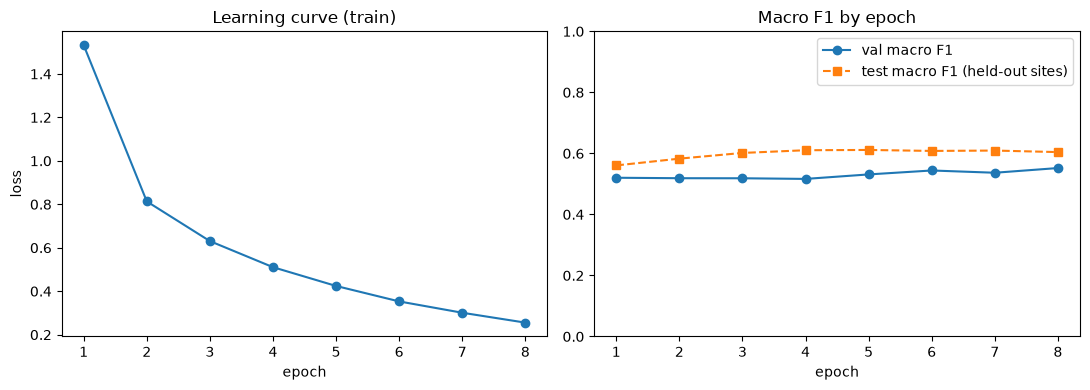

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(hist.epoch, hist.train_loss, "o-", label="train cross-entropy")
ax[0].set_xlabel("epoch"); ax[0].set_ylabel("loss"); ax[0].set_title("Learning curve (train)")
ax[1].plot(hist.epoch, hist.val_macro_f1, "o-", label="val macro F1")
ax[1].plot(hist.epoch, hist.test_macro_f1, "s--", label="test macro F1 (held-out sites)")
ax[1].set_xlabel("epoch"); ax[1].set_ylim(0, 1); ax[1].legend(); ax[1].set_title("Macro F1 by epoch")
plt.tight_layout()
plt.savefig(OUT / "learning_curves.png", dpi=120)
print("final epoch:", hist.iloc[-1].to_dict())

## 4. What the model gets wrong

Macro F1 alone will not survive the viva; the confusion matrix shows *which* confusions cause it, and `empty` in the columns is the false-alert fuel.

,model,val_macro_f1,val_accuracy,test_macro_f1,test_accuracy
0,majority_class,0.0292,0.2344,0.0201,0.1503
1,random,0.0613,0.0742,0.0645,0.0731
2,baseline_logreg_frozen_resnet50,0.5400,0.6459,0.6245,0.7623
3,finetuned_resnet50,0.5520,0.6756,0.6043,0.7320


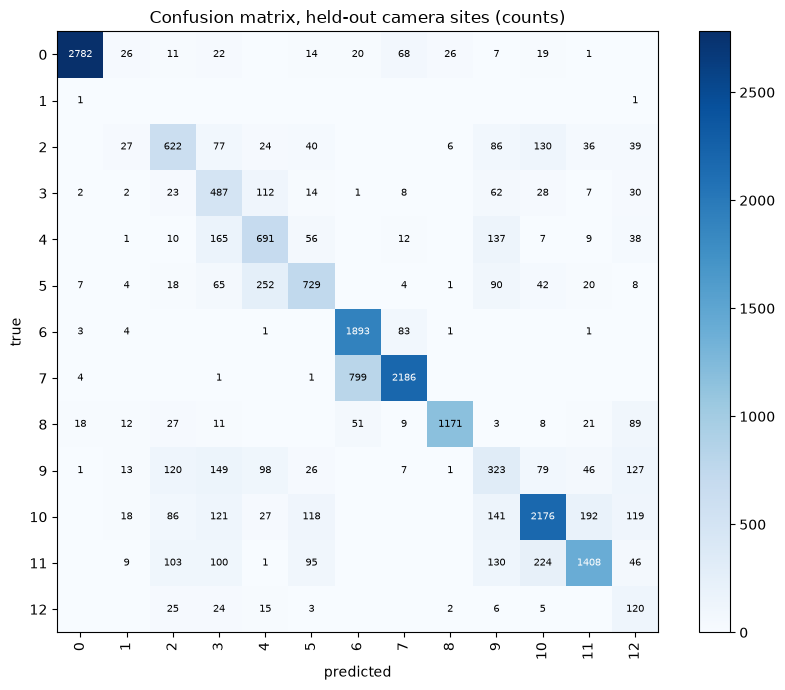

In [7]:
probs = []
model.eval()
with torch.no_grad():
    for x, y in loaders["test"]:
        probs.append(model(x.to(DEVICE)).cpu().numpy())
probs = np.concatenate(probs)
yhat = probs.argmax(1)
ytest = np.concatenate([y.numpy() for _, y in loaders["test"]])
cm = W.confusion(ytest, yhat, labels=LABELS)
fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(N_CLASSES)); ax.set_yticks(range(N_CLASSES))
ax.set_xticklabels(class_map.index, rotation=90); ax.set_yticklabels(class_map.index)
for i in range(N_CLASSES):
    for j in range(N_CLASSES):
        if cm[i, j] > 0:
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=7,
                    color="white" if cm[i, j] > cm.max() / 2 else "black")
ax.set_xlabel("predicted"); ax.set_ylabel("true")
ax.set_title("Confusion matrix, held-out camera sites (counts)")
plt.colorbar(im, ax=ax, fraction=0.04)
plt.tight_layout()
plt.savefig(OUT / "confusion_test.png", dpi=120)
final_metrics = W.metrics(ytest, yhat, labels=LABELS)
comparison = pd.concat([baseline_df, pd.DataFrame([{
    "model": "finetuned_resnet50",
    "val_macro_f1": float(hist.iloc[-1]["val_macro_f1"]),
    "val_accuracy": float(hist.iloc[-1]["val_accuracy"]),
    "test_macro_f1": round(final_metrics["macro_f1"], 4),
    "test_accuracy": round(final_metrics["accuracy"], 4),
}])], ignore_index=True)
comparison

In [8]:
per_class = pd.DataFrame([{"label": l, "class_name": class_map.get(l, "?"),
                           "f1": final_metrics["per_class_f1"].get(l, 0.0),
                           "test_images": int((ytest == l).sum())} for l in LABELS])
per_class["wrongly_called_empty"] = [int(cm[l][0]) for l in LABELS]
per_class["false_alerts_on_empty"] = [int(cm[0][l]) for l in LABELS]
per_class = per_class.sort_values("f1")
print("false alerts (empty frames called an animal):", int(cm[0][1:].sum()), "of", int(cm[0].sum()), "empty test frames")
print("species recall over non-empty frames:",
      round(float((cm[1:, 1:].sum(1) / cm[1:].sum(1).clip(min=1)).mean()), 4))
per_class.to_string(index=False)

false alerts (empty frames called an animal): 214 of 2996 empty test frames
species recall over non-empty frames: 0.9563


' label               class_name     f1  test_images  wrongly_called_empty  false_alerts_on_empty\n     1           tayassu pecari 0.0000            2                     1                     26\n    12            mazama temama 0.2938          200                     0                      0\n     9 urocyon cinereoargenteus 0.3271          990                     1                      7\n     3            puma concolor 0.4875          776                     2                     22\n     2      dasyprocta punctata 0.5835         1087                     0                     11\n     4       leopardus pardalis 0.5888         1126                     0                      0\n     5            panthera onca 0.6241         1240                     7                     14\n    11               crax rubra 0.7301         2116                     0                      1\n    10       meleagris ocellata 0.7614         2998                     0                     19\n     6             

## 5. Experiment log

One machine-readable row per run — seed, split hashes, preprocessing, hyperparameters, metrics, runtime and hardware — because the rubric requires experiment records, not screenshots.

In [9]:
split_hash = {s: str(pd.read_csv(SPLITS_DIR / f"{s}.csv").shape) for s in ("train", "val", "test")}
run = {
    "run_utc": pd.Timestamp.now(tz="UTC").isoformat(),
    "experiment": "notebook02_baseline_vs_finetune",
    "seed": SEED, "splits": split_hash, "n_classes": N_CLASSES,
    "classes": class_map.tolist(),
    "preprocessing": "RandomResizedCrop224 + hflip + colorjitter (train), resize224 + ImageNet norm (eval)",
    "optimizer": f"AdamW lr={LR}", "loss": "CrossEntropyLoss(class weights)",
    "epochs": EPOCHS, "batch": BATCH, "unfrozen": "fc,layer4",
    "baseline_val_macro_f1": float(baseline_df.set_index("model").loc["baseline_logreg_frozen_resnet50", "val_macro_f1"]),
    "baseline_test_macro_f1": float(baseline_df.set_index("model").loc["baseline_logreg_frozen_resnet50", "test_macro_f1"]),
    "finetune_test_macro_f1": round(final_metrics["macro_f1"], 4),
    "delta_vs_baseline": round(final_metrics["macro_f1"]
                               - float(baseline_df.set_index("model").loc["baseline_logreg_frozen_resnet50", "test_macro_f1"]), 4),
    "feature_extract_sec": extract_sec, "train_sec": round(time.time() - t0, 1),
    "hardware": W.hardware_note(),
}
log_path = OUT / "experiment_log.jsonl"
with open(log_path, "a", encoding="utf-8") as fh:
    fh.write(json.dumps(run) + "\n")
print(json.dumps({k: run[k] for k in ("baseline_test_macro_f1", "finetune_test_macro_f1", "delta_vs_baseline")}, indent=2))
torch.save(model.state_dict(), OUT / "resnet50_layer4.pt")
print("saved", OUT / "resnet50_layer4.pt")

{
  "baseline_test_macro_f1": 0.6245,
  "finetune_test_macro_f1": 0.6043,
  "delta_vs_baseline": -0.0202
}


saved C:\Users\xxshi\Desktop\PYTHOM\DL_PBL\outputs\logs\notebook02_full\resnet50_layer4.pt


Read the delta before celebrating: if fine-tuning does not beat frozen features by a wide margin on held-out *camera sites*, the backbone is not the bottleneck and the extra training is unjustified. The pre-registered comparison for Phase I is this pair, same seed, same split hashes, same augmentation, differing only in which parameters receive gradients — that is what makes it an ablation rather than two unrelated runs.